<a href="https://colab.research.google.com/github/Timoteogon/Puntos-de-lagrange/blob/main/puntos_de_lagrange.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Puntos de Lagrange en el sistema Sol–Tierra

Problema restringido de tres cuerpos en el sistema rotante: Sol y Tierra giran en órbita circular alrededor de su baricentro y una partícula de masa despreciable se mueve bajo su influencia. Se grafica el potencial efectivo y se buscan sus puntos de equilibrio (L1–L5).

### Librerías

In [161]:
!pip install -Uq pymcel

In [162]:
import pymcel as pc
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from celluloid import Camera
import numpy as np
import plotly.graph_objects as go

### Constantes y unidades

Se usan unidades adimensionales: $G = 1$, distancia Sol–Tierra $a = 1$ y masa de la Tierra $= 1$.

La masa del Sol (30) es un valor ficticio, no el real ($\approx 3\times10^5$ masas terrestres). Con una razón de masas más moderada, los puntos de Lagrange se ven mejor en la gráfica.

La razón de masas es
$$\mu = \frac{m_\oplus}{m_\odot + m_\oplus}$$

In [163]:
grados = np.pi/180
G = 1
a = 1
masa_tierra = 1
masa_sol = 30 # valor de Gemini AI
masa = masa_tierra + masa_sol
mu = masa_tierra/masa

### Posición de los cuerpos

Con el origen en el baricentro y el eje $x$ pasando por ambos cuerpos

- Sol: $(-\mu,\ 0)$
- Tierra: $(1-\mu,\ 0)$

In [164]:
# posicion del Sol
pos_sol = [-mu, 0]

# posicion de la Tierra
pos_tierra = [1 - mu, 0]

## Movimiento medio (tercera ley de Kepler)

Velocidad angular con la que rota el sistema de referencia:

$$n = \sqrt{\frac{G\,(m_\odot + m_\oplus)}{a^3}}$$

In [165]:
n = np.sqrt(G*masa/a**3)

## Potencial efectivo

Para un cuerpo de masa unitaria, el potencial gravitacional de los dos cuerpos es

$$U_{grav} = -\frac{G\,m_\odot}{r_S} - \frac{G\,m_\oplus}{r_T}, \qquad \vec F = -\nabla U$$

Pero en el sistema rotante también hay que sumar el término centrífugo, así que el potencial relevante es el **efectivo**:

$$\Phi_{ef}(x,y) = -\frac{G\,m_\odot}{r_S} - \frac{G\,m_\oplus}{r_T} - \frac{1}{2}\,n^2\,(x^2+y^2)$$

con las distancias de la partícula $(x,y)$ a cada cuerpo:

$$r_S=\sqrt{(x+\mu)^2+y^2}, \qquad r_T=\sqrt{(x-(1-\mu))^2+y^2}$$

Los puntos de Lagrange son los puntos donde $\nabla \Phi_{ef} = 0$.

### Malla de puntos

Se construye una malla polar ($r$ de 0 a 1.5, 629 ángulos) y se pasa a coordenadas cartesianas $(x, y)$ para evaluar el potencial.

In [166]:
r = np.linspace(0, 1.5, 151)
theta = np.linspace(0, 2*np.pi, 629, endpoint=False)

x = []
y = []

for i in range(len(r)):
  for j in range(len(theta)):
    xi = r[i]*np.cos(theta[j])
    yi = r[i]*np.sin(theta[j])
    x.append(xi)
    y.append(yi)

### Evaluación del potencial en cada punto

In [167]:
Phi = []

for i in range(len(x)):
    ds = np.sqrt((x[i] + mu)**2 + y[i]**2)
    dt = np.sqrt((x[i] - (1 - mu))**2 + y[i]**2)
    phii= -(G*masa_sol/ds) - (G*masa_tierra/dt) - 1/2*G*masa/a**3*(x[i]**2 + y[i]**2)
    Phi.append(phii)

print(len(x))
print(len(y))
print(len(Phi))

94979
94979
94979


### Reorganizar a matrices

Se reorganizan $x$, $y$ y $\Phi$ en matrices de forma $(151, 629)$ para poder usar `contour`.

In [168]:
X = np.array(x).reshape(len(r), len(theta))
Y = np.array(y).reshape(len(r), len(theta))
Phi_malla = np.array(Phi).reshape(len(r), len(theta))

print(X.shape)
print(Y.shape)
print(Phi_malla.shape)

(151, 629)
(151, 629)
(151, 629)


### Normalización

Se divide entre la masa total: $U = \Phi_{ef}/M$.

In [169]:
U = Phi_malla/masa   # U_ef / M

In [170]:
print("Potencial mínimo:", np.min(Phi_malla))
print("Potencial máximo:", np.max(Phi_malla))
print("mu:", mu)

Potencial mínimo: -13255.39038989448
Potencial máximo: -46.01697289429738
mu: 0.03225806451612903


In [171]:
print(np.percentile(Phi_malla, [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 100]))

[-13255.39038989  -1030.23291215   -407.66972191   -203.94265293
    -83.78493078    -53.2981784     -48.50400964    -46.93477294
    -46.51872642    -46.11930225    -46.01697289]


### Curvas de nivel del potencial efectivo

Los niveles son finos cerca de $U \approx -1.5$ y más espaciados lejos de ahí. En esa zona se ven las sillas de potencial (L1, L2, L3) y los máximos (L4, L5).

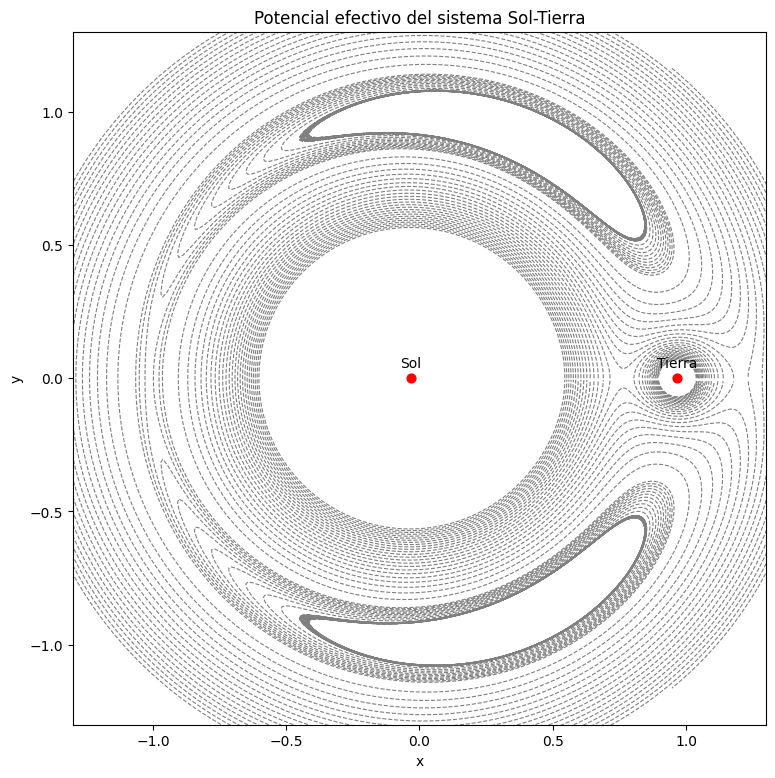

In [173]:
# --- Malla polar vectorizada, refinada cerca de r = 1 ---
r = np.concatenate([
    np.linspace(0.05, 0.95, 300, endpoint=False),
    np.linspace(0.95, 1.05, 2500, endpoint=False),
    np.linspace(1.05, 1.6, 300)
])

# --- Niveles: finos cerca de -1.5 y espaciados lejos ---
niveles = np.unique(np.concatenate([
    np.linspace(-1.9,    -1.52,   25),
    np.linspace(-1.52,   -1.5008, 12),
    np.linspace(-1.5008, -1.4999, 60),   # aquí se ven las sillas y L4/L5
]))

fig, ax = plt.subplots(figsize=(9, 9))

ax.contour(X, Y, U, levels=niveles, colors='gray', linewidths=0.8)

ax.scatter([-mu, 1-mu], [0, 0], color='red', s=40, zorder=3)
ax.annotate('Sol',    (-mu, 0),  textcoords='offset points', xytext=(0, 8), ha='center')
ax.annotate('Tierra', (1-mu, 0), textcoords='offset points', xytext=(0, 8), ha='center')

ax.set_aspect('equal')
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Potencial efectivo del sistema Sol-Tierra')

plt.show()